# Department of Computing
## EE348: Knowledge Representation and Reasoning in AI
### Lab 9: Rule-Based Knowledge Representation and Reasoning in Python

- **Student Name:** Muhammad Sikandar Hussain
- **CMS ID:** 502808
- **Class:** BSAI-2024A
- **Date:** 12-11-2026 | **Time:** 02:00 to 05:00 (3 Hours)
- **Course Instructor:** Dr. Saqib Nawaz
- **Lab Engineer:** Syed Muhammad Ali Musa
- **CLO 1:** Understand various knowledge representation formalisms and reasoning techniques

---

### Executive Overview & Lab Objectives
Rule-based systems represent one of the foundational paradigms of symbolic artificial intelligence and knowledge engineering. Following our formalization of Description Logics and ontologies in earlier labs, this laboratory investigates executable **IF-THEN production rules** operating over a university course-advising and academic decision-support domain.

In this laboratory, we develop a transparent, modular rule engine in pure Python. Key objectives include:
1. **Knowledge Representation:** Formalize positive ground assertions (facts) using Python tuples and implication schemas (rules) using dictionaries.
2. **Variable Unification & Relational Joins:** Implement pattern matching and variable binding across multi-premise conjunctive antecedents (AND conditions) ensuring consistent variable assignment across conditions.
3. **Data-Driven Forward Chaining:** Implement a forward reasoning engine that iteratively matches premises, instantiates consequents, prevents duplicates, records a step-by-step causal inference trace, and terminates at a monotonic fixed point.
4. **Goal-Directed Backward Chaining:** Implement a recursive top-down backward prover that navigates AND premises and OR alternative rules, utilizing a cycle-detection visiting set to prevent infinite recursion, while adhering to the Open-World Assumption (OWA).
5. **Relational Joins & Prerequisite Completeness:** Model multi-variable course prerequisite relationships, contrasting element-wise condition satisfaction from universal requirement completeness under Closed-World Assumptions.
6. **Agenda Management & Conflict Resolution:** Investigate salience/priority scheduling, proving that execution order alters activation sequences but leaves the final positive deductive closure invariant.
7. **Semantic Conflict & Policy Auditing:** Separate operational rule conflicts from logical/policy incompatibilities, explaining why coexisting positive atoms require explicit domain integrity axioms to produce classical contradictions.
8. **Mini Expert System Challenge:** Design, execute, and validate an end-to-end scholarship advising expert system featuring multi-path reasoning, intermediate concept derivation, open-world unknown handling, visual proof/dependency graphs, and an in-depth data quality critique.

## Task 1 — Represent Facts, Rules and Queries

### Theoretical Background
A rule-based knowledge representation system partitions domain knowledge into:
- **Ground Facts:** Unconditional positive atomic assertions about individuals in the universe of discourse (e.g., `("Student", "Ali")`, `("Completed", "Ali", "CS101")`). Ground facts contain constants and no free variables.
- **Rules (Production Rules / Horn Clauses):** Conditional implication schemas of the form:
  $$\text{Antecedent (Premises / Body)} \implies \text{Consequent (Conclusion / Head)}$$
  In our teaching engine, rule antecedents are represented as lists of condition tuples, consequents as single conclusion tuples, and variables are prefixed with `?` (e.g., `?x`).
- **Goal Queries:** Ground atomic propositions whose truth value relative to working memory is evaluated (e.g., `("CanApply", "Ali", "AI201")`).

Below, we represent the baseline university course-advising knowledge base.

In [1]:
# Task 1: Ground facts, rules, and goal query representation
facts = {
    ("Student", "Ali"),
    ("Completed", "Ali", "CS101"),
    ("Student", "Sara"),
    ("Completed", "Sara", "EE101")
}

rules = [
    {
        "id": "R1",
        "if": [("Completed", "?x", "CS101")],
        "then": ("PrerequisiteMet", "?x"),
        "priority": 1
    },
    {
        "id": "R2",
        "if": [("Student", "?x"), ("PrerequisiteMet", "?x")],
        "then": ("Eligible", "?x", "AI201"),
        "priority": 1
    },
    {
        "id": "R3",
        "if": [("Eligible", "?x", "AI201")],
        "then": ("CanApply", "?x", "AI201"),
        "priority": 1
    }
]

goal = ("CanApply", "Ali", "AI201")

print("--- Task 1: Base Knowledge Base ---")
print("Ground facts (sorted):")
for f in sorted(facts):
    print(f"  {f}")

print("\nRule base definitions:")
for r in rules:
    print(f"  [{r['id']}] IF {r['if']} THEN {r['then']} (priority={r['priority']})")

print(f"\nTarget Goal Query: {goal}")

--- Task 1: Base Knowledge Base ---
Ground facts (sorted):
  ('Completed', 'Ali', 'CS101')
  ('Completed', 'Sara', 'EE101')
  ('Student', 'Ali')
  ('Student', 'Sara')

Rule base definitions:
  [R1] IF [('Completed', '?x', 'CS101')] THEN ('PrerequisiteMet', '?x') (priority=1)
  [R2] IF [('Student', '?x'), ('PrerequisiteMet', '?x')] THEN ('Eligible', '?x', 'AI201') (priority=1)
  [R3] IF [('Eligible', '?x', 'AI201')] THEN ('CanApply', '?x', 'AI201') (priority=1)

Target Goal Query: ('CanApply', 'Ali', 'AI201')


### Task 1 Exercise: Entity Classification & Rule Anatomy
**Exercise Requirements:**
1. Add `Student(Hina)` and `Completed(Hina, CS101)` to the ground facts.
2. Classify `Student(Ali)`, `R2`, and `CanApply(Ali, AI201)?` as fact, rule, or query.
3. Formally identify the antecedent (body/premises) and consequent (head/conclusion) of Rule `R2`.

In [2]:
# Task 1 Exercise: Add facts for Hina and perform entity classification
facts.add(("Student", "Hina"))
facts.add(("Completed", "Hina", "CS101"))

print("--- Task 1 Exercise: Updated Ground Facts ---")
for f in sorted(facts):
    print(f"  {f}")

# 2. Entity Classifications
classification_data = [
    ("Student(Ali)", "Fact", "Ground positive assertion containing only constants; asserts Ali belongs to the Student concept."),
    ("R2", "Rule", "Conditional Horn schema relating two antecedent conditions with free variable ?x to a consequent."),
    ("CanApply(Ali, AI201)?", "Query / Goal", "Target proposition submitted to the inference engine to determine deductive entailment.")
]

print("\n--- Formal Entity Classification Table ---")
print(f"{'Entity':<25} | {'Formal Class':<14} | {'Knowledge Engineering Role'}")
print("-" * 90)
for ent, cls, role in classification_data:
    print(f"{ent:<25} | {cls:<14} | {role}")

# 3. Antecedent and Consequent Breakdown for Rule R2
r2_rule = next(r for r in rules if r["id"] == "R2")
print("\n--- Structural Decomposition of Rule R2 ---")
print(f"Rule Identifier : {r2_rule['id']}")
print(f"Antecedent (IF) : {r2_rule['if']}")
print("  Condition 1   : ('Student', '?x')")
print("  Condition 2   : ('PrerequisiteMet', '?x')")
print(f"Consequent (THEN): {r2_rule['then']}")
print(f"Binding Variable: '?x' (enforces that the student instance must satisfy both premises)")

--- Task 1 Exercise: Updated Ground Facts ---
  ('Completed', 'Ali', 'CS101')
  ('Completed', 'Hina', 'CS101')
  ('Completed', 'Sara', 'EE101')
  ('Student', 'Ali')
  ('Student', 'Hina')
  ('Student', 'Sara')

--- Formal Entity Classification Table ---
Entity                    | Formal Class   | Knowledge Engineering Role
------------------------------------------------------------------------------------------
Student(Ali)              | Fact           | Ground positive assertion containing only constants; asserts Ali belongs to the Student concept.
R2                        | Rule           | Conditional Horn schema relating two antecedent conditions with free variable ?x to a consequent.
CanApply(Ali, AI201)?     | Query / Goal   | Target proposition submitted to the inference engine to determine deductive entailment.

--- Structural Decomposition of Rule R2 ---
Rule Identifier : R2
Antecedent (IF) : [('Student', '?x'), ('PrerequisiteMet', '?x')]
  Condition 1   : ('Student', '?x')

**Interpretation of Results (Task 1):**
Ground facts provide positive atomic knowledge regarding specific named individuals in the domain (Ali, Sara, Hina), stored inside Python sets as tuples to enforce uniqueness and set-membership semantics. Rules express universal conditional assertions using pattern variables (e.g., `?x`), where Rule R2 specifies that any individual satisfying both `Student(?x)` and `PrerequisiteMet(?x)` entails `Eligible(?x, AI201)`. The goal represents a target query whose truth value is not initially declared as a ground fact, requiring forward or backward inference over working memory to determine whether it is logically entailed.

## Task 2 — Implement Variable Matching and AND Conditions

### Theoretical Background
Pattern matching in first-order Horn rule systems requires **unification**:
- An atomic condition matches a ground fact if each term matches: constants must match exactly (`term == value`), while variables (`?x`) bind to the corresponding ground constant.
- **Variable Consistency (Cross-Condition Equijoin):** When multiple conditions in a rule antecedent share the same variable (e.g., `?x` in `Student(?x)` and `PrerequisiteMet(?x)`), the variable must bind to the *identical* constant in all premises. If condition 1 binds `?x` to `Ali`, condition 2 cannot match a fact where the corresponding term is `Sara`.
- `match_all` evaluates a list of conjunctive conditions (AND) sequentially against working memory, propagating and filtering consistent substitutions across each premise.

In [3]:
# Task 2: Core pattern matching, unification, and instantiation
def is_var(x):
    """Checks whether a term is a pattern variable (starts with '?')."""
    return isinstance(x, str) and x.startswith("?")

def unify(pattern, fact, bindings):
    """Attempts to unify pattern with a ground fact given existing variable bindings.
    Returns an updated bindings dictionary on success, or None on failure."""
    if len(pattern) != len(fact):
        return None
    result = dict(bindings)
    for term, value in zip(pattern, fact):
        if is_var(term):
            if term in result and result[term] != value:
                return None  # Inconsistent variable binding
            result[term] = value
        elif term != value:
            return None  # Constant mismatch
    return result

def match_all(conditions, known):
    """Finds all consistent variable bindings satisfying all conjunctive conditions (AND).
    Operates as an equijoin across working memory facts."""
    matches = [{}]
    for cond in conditions:
        next_matches = []
        for binding in matches:
            for fact in sorted(known):
                found = unify(cond, fact, binding)
                if found is not None:
                    next_matches.append(found)
        matches = next_matches
    return matches

def instantiate(pattern, binding):
    """Replaces variables in a pattern tuple with their ground values from binding."""
    return tuple(binding.get(term, term) for term in pattern)

print("--- Task 2: Base Pattern Matching ---")
print("R1 antecedent condition:", rules[0]["if"])
print("R1 bindings on facts:", match_all(rules[0]["if"], facts))

print("\nR2 antecedent conditions:", rules[1]["if"])
print("R2 bindings on initial facts (before inference):", match_all(rules[1]["if"], facts))

--- Task 2: Base Pattern Matching ---
R1 antecedent condition: [('Completed', '?x', 'CS101')]
R1 bindings on facts: [{'?x': 'Ali'}, {'?x': 'Hina'}]

R2 antecedent conditions: [('Student', '?x'), ('PrerequisiteMet', '?x')]
R2 bindings on initial facts (before inference): []


### Task 2 Exercise: Sara's Completion, Conjunctive Matching, and Join Clashes
**Exercise Requirements:**
1. Add `Completed(Sara, CS101)` to `facts` and re-evaluate `R1` bindings.
2. Test a two-premise conjunctive rule: `[("Student", "?x"), ("Completed", "?x", "CS101")]`.
3. Provide a concrete demonstration showing why two different students cannot be combined into one valid match.

In [4]:
# Task 2 Exercise: Adding Completed(Sara, CS101)
facts.add(("Completed", "Sara", "CS101"))
r1_updated_matches = match_all(rules[0]["if"], facts)
print("--- Task 2 Exercise: R1 Bindings After Adding Completed(Sara, CS101) ---")
print("R1 matches:", r1_updated_matches)

# 2. Test two-premise rule: Student(?x) AND Completed(?x, CS101)
two_premise_conds = [("Student", "?x"), ("Completed", "?x", "CS101")]
two_premise_matches = match_all(two_premise_conds, facts)

print("\n--- Two-Premise Rule Matching: Student(?x) AND Completed(?x, CS101) ---")
print(f"Conditions: {two_premise_conds}")
print(f"Matches found: {len(two_premise_matches)}")
for m in two_premise_matches:
    print(f"  Valid substitution: {m} -> satisfies both premises simultaneously")

# 3. Demonstration: Cross-Condition Variable Consistency Clash
print("\n--- Demonstration: Why Distinct Students Cannot Combine into One Match ---")
fact_student_ali = ("Student", "Ali")
fact_completed_sara = ("Completed", "Sara", "CS101")

# Step 1: Match first premise against Ali
b1 = unify(("Student", "?x"), fact_student_ali, {})
print(f"Step 1: Unify ('Student', '?x') with {fact_student_ali} -> Binding: {b1}")

# Step 2: Attempt to match second premise against Sara using Ali's binding
b2 = unify(("Completed", "?x", "CS101"), fact_completed_sara, b1)
print(f"Step 2: Unify ('Completed', '?x', 'CS101') with {fact_completed_sara} using prior binding {b1} -> Binding: {b2}")
print("Explanation: Unification returns None because '?x' is already bound to 'Ali',")
print("             whereas fact_completed_sara has constant 'Sara'. Since 'Ali' != 'Sara',")
print("             the engine rejects the hybrid binding, enforcing relational consistency.")

--- Task 2 Exercise: R1 Bindings After Adding Completed(Sara, CS101) ---
R1 matches: [{'?x': 'Ali'}, {'?x': 'Hina'}, {'?x': 'Sara'}]

--- Two-Premise Rule Matching: Student(?x) AND Completed(?x, CS101) ---
Conditions: [('Student', '?x'), ('Completed', '?x', 'CS101')]
Matches found: 3
  Valid substitution: {'?x': 'Ali'} -> satisfies both premises simultaneously
  Valid substitution: {'?x': 'Hina'} -> satisfies both premises simultaneously
  Valid substitution: {'?x': 'Sara'} -> satisfies both premises simultaneously

--- Demonstration: Why Distinct Students Cannot Combine into One Match ---
Step 1: Unify ('Student', '?x') with ('Student', 'Ali') -> Binding: {'?x': 'Ali'}
Step 2: Unify ('Completed', '?x', 'CS101') with ('Completed', 'Sara', 'CS101') using prior binding {'?x': 'Ali'} -> Binding: None
Explanation: Unification returns None because '?x' is already bound to 'Ali',
             whereas fact_completed_sara has constant 'Sara'. Since 'Ali' != 'Sara',
             the engine reje

**Interpretation of Results (Task 2):**
The unification algorithm correctly enforces first-order variable binding consistency across conjunctive conditions. When `Completed(Sara, CS101)` was added, `R1` produced matches for Ali, Hina, and Sara because each independently completed CS101. Crucially, the two-premise test demonstrates that the system prevents invalid cross-individual joins: an individual who is a student cannot satisfy the completion condition using another individual's coursework, because the shared variable `?x` demands strict identity across all antecedent premises.

## Task 3 — Forward Chaining: Match, Fire and Stop

### Theoretical Background
**Forward Chaining (Data-Driven Reasoning):**
- Begins with the initial working memory (known ground facts).
- Iteratively searches for rule antecedent instantiations that match known facts.
- Computes new ground conclusions via substitution (`instantiate`).
- **Duplicate Prevention:** Avoids re-adding already-known or concurrently-derived facts, preventing cyclic firing and infinite loops.
- **Inference Trace:** Records each firing step `(rule_id, conclusion, binding)` to construct a transparent audit trail of deductions.
- **Fixed-Point Semantics:** Continues in rounds until an iteration produces zero new facts (`additions == []`), reaching the unique deductive closure of the positive Horn rulebase.

In [5]:
# Task 3: Forward Chaining Engine
def forward_chain(initial, rulebase):
    """Computes the deductive closure of a positive Horn rulebase over initial facts.
    Returns (known_facts, inference_trace)."""
    known, trace = set(initial), []
    iteration = 0
    while True:
        iteration += 1
        additions = []
        for rule in rulebase:
            for binding in match_all(rule["if"], known):
                conclusion = instantiate(rule["then"], binding)
                if conclusion not in known and conclusion not in [x[1] for x in additions]:
                    additions.append((rule["id"], conclusion, binding))
        if not additions:
            break
        for rule_id, conclusion, binding in additions:
            known.add(conclusion)
            trace.append((rule_id, conclusion, binding))
    return known, trace

# Reset to base facts (Ali and Sara original records) for Task 3 baseline verification
base_facts = {
    ("Student", "Ali"),
    ("Completed", "Ali", "CS101"),
    ("Student", "Sara"),
    ("Completed", "Sara", "EE101")
}

closure, trace = forward_chain(base_facts, rules)

print("--- Task 3: Base Forward Chaining Trace ---")
for step, (rid, conclusion, binding) in enumerate(trace, 1):
    print(f"Step {step}: Rule [{rid}] => {conclusion} using {binding}")

print(f"\nIs goal {goal} in deductive closure? -> {goal in closure}")

--- Task 3: Base Forward Chaining Trace ---
Step 1: Rule [R1] => ('PrerequisiteMet', 'Ali') using {'?x': 'Ali'}
Step 2: Rule [R2] => ('Eligible', 'Ali', 'AI201') using {'?x': 'Ali'}
Step 3: Rule [R3] => ('CanApply', 'Ali', 'AI201') using {'?x': 'Ali'}

Is goal ('CanApply', 'Ali', 'AI201') in deductive closure? -> True


### Task 3 Exercise: Causal Chain Analysis, Cohort Expansion, and Fixed-Point Invariance
**Exercise Requirements:**
1. Explain step-by-step why the sequence `R1 -> R2 -> R3` yields `CanApply(Ali, AI201)`.
2. Repeat forward chaining with Hina included (`Student(Hina)` and `Completed(Hina, CS101)`).
3. Run forward chaining a second time on the resulting closure to verify that no new facts appear.
4. Explain formally what stops the engine.

In [6]:
# Task 3 Exercise: Forward Chaining with Hina Included
facts_with_hina = base_facts | {
    ("Student", "Hina"),
    ("Completed", "Hina", "CS101")
}

closure_hina, trace_hina = forward_chain(facts_with_hina, rules)

print("--- Task 3 Exercise: Forward Chaining Trace with Hina ---")
for step, (rid, conclusion, binding) in enumerate(trace_hina, 1):
    print(f"Step {step:2d}: [{rid}] => {str(conclusion):<28} using {binding}")

print("\n--- Query Evaluations on Deductive Closure ---")
for student in ["Ali", "Hina", "Sara"]:
    st_goal = ("CanApply", student, "AI201")
    print(f"  {st_goal} -> {st_goal in closure_hina}")

# Re-running forward chaining on the already computed closure
print("\n--- Fixed-Point Verification: Re-running on Computed Closure ---")
closure_second, trace_second = forward_chain(closure_hina, rules)
print(f"Number of new facts derived on second run : {len(trace_second)}")
print(f"Is closure_second identical to closure_hina? : {closure_second == closure_hina}")
print(f"Fixed point successfully attained at Iteration 1 of second pass.")

--- Task 3 Exercise: Forward Chaining Trace with Hina ---
Step  1: [R1] => ('PrerequisiteMet', 'Ali')   using {'?x': 'Ali'}
Step  2: [R1] => ('PrerequisiteMet', 'Hina')  using {'?x': 'Hina'}
Step  3: [R2] => ('Eligible', 'Ali', 'AI201') using {'?x': 'Ali'}
Step  4: [R2] => ('Eligible', 'Hina', 'AI201') using {'?x': 'Hina'}
Step  5: [R3] => ('CanApply', 'Ali', 'AI201') using {'?x': 'Ali'}
Step  6: [R3] => ('CanApply', 'Hina', 'AI201') using {'?x': 'Hina'}

--- Query Evaluations on Deductive Closure ---
  ('CanApply', 'Ali', 'AI201') -> True
  ('CanApply', 'Hina', 'AI201') -> True
  ('CanApply', 'Sara', 'AI201') -> False

--- Fixed-Point Verification: Re-running on Computed Closure ---
Number of new facts derived on second run : 0
Is closure_second identical to closure_hina? : True
Fixed point successfully attained at Iteration 1 of second pass.


**Interpretation of Results (Task 3):**
The sequence `R1 -> R2 -> R3` represents a classic forward-chaining causal derivation:
1. `R1` matches `Completed(Ali, CS101)`, deriving intermediate fact `PrerequisiteMet(Ali)`.
2. `R2` joins `Student(Ali)` with the newly derived `PrerequisiteMet(Ali)`, deriving `Eligible(Ali, AI201)`.
3. `R3` matches `Eligible(Ali, AI201)`, yielding the final target `CanApply(Ali, AI201)`.

When Hina was added, the engine derived identical intermediate and final facts for Hina in parallel, while Sara derived nothing because `EE101` does not satisfy `CS101`. Re-running forward chaining directly on the closure derived zero new facts; the engine halts because `additions` evaluates to empty, formally verifying that a monotonic fixed point (deductive closure) has been reached.

## Task 4 — Backward Chaining: Prove a Goal

### Theoretical Background
**Backward Chaining (Goal-Directed Reasoning):**
- Starts with a specific ground query / goal hypothesis and works backward to find supporting evidence.
- **AND/OR Tree Search:**
  - **OR Nodes (Alternative Rules):** A goal can be proved if *any* rule concluding the goal succeeds, or if the goal is already an asserted ground fact.
  - **AND Nodes (Conjunctive Premises):** For a specific rule to fire, *all* antecedent premises must be simultaneously proved.
- **Cycle Prevention:** A `visiting` set of active sub-goals prevents infinite recursion when traversing cyclic rule dependencies.
- **Open-World Assumption (OWA):** If a goal cannot be proved from the rulebase and facts, the engine returns `UNKNOWN` (not proved), rather than assuming the proposition is false.

In [7]:
# Task 4: Backward Chaining Prover
def prove(goal, known, rulebase, visiting=frozenset()):
    """Goal-directed backward chaining prover with cycle detection.
    Returns (success_bool, proof_tree)."""
    if goal in known:
        return True, ("FACT", goal)
    if goal in visiting:
        return False, ("CYCLE", goal)
    for rule in rulebase:
        binding = unify(rule["then"], goal, {})
        if binding is None:
            continue
        premises = [instantiate(c, binding) for c in rule["if"]]
        # Restricted prover: all premise variables must be fully bound by the goal
        if any(is_var(t) for c in premises for t in c):
            continue
        children = [prove(c, known, rulebase, visiting | {goal}) for c in premises]
        if all(ok for ok, _ in children):
            return True, (rule["id"], goal, [tree for _, tree in children])
    return False, ("UNKNOWN", goal)

print("--- Task 4: Base Backward Chaining Queries ---")
for query in [("CanApply", "Ali", "AI201"), ("CanApply", "Sara", "AI201")]:
    success, tree = prove(query, base_facts, rules)
    print(f"\nQuery: {query} -> {'PROVED' if success else 'NOT PROVED'}")
    print(f"Raw Proof Tree Structure:\n  {tree}")

--- Task 4: Base Backward Chaining Queries ---

Query: ('CanApply', 'Ali', 'AI201') -> PROVED
Raw Proof Tree Structure:
  ('R3', ('CanApply', 'Ali', 'AI201'), [('R2', ('Eligible', 'Ali', 'AI201'), [('FACT', ('Student', 'Ali')), ('R1', ('PrerequisiteMet', 'Ali'), [('FACT', ('Completed', 'Ali', 'CS101'))])])])

Query: ('CanApply', 'Sara', 'AI201') -> NOT PROVED
Raw Proof Tree Structure:
  ('UNKNOWN', ('CanApply', 'Sara', 'AI201'))


### Task 4 Exercise: Hierarchical Proof Trees, OR Branching, Visual Graph, and OWA Semantics
**Exercise Requirements:**
1. Draw and format the proof tree for `CanApply(Ali, AI201)`, clearly labelling rules R3, R2, R1 and base facts.
2. Render a high-resolution visual proof tree using `networkx` and `matplotlib`.
3. Add a second alternative route to `CanApply` using an exemption/waiver rule to demonstrate OR reasoning.
4. Explain why returning `"NOT PROVED"` does not establish a negative fact in classical logic.

--- Task 4 Exercise: Hierarchical ASCII Proof Tree for Ali ---
├── [RULE R3] Goal: ('CanApply', 'Ali', 'AI201')
    ├── [RULE R2] Goal: ('Eligible', 'Ali', 'AI201')
        └── [GROUND FACT] ('Student', 'Ali')
        ├── [RULE R1] Goal: ('PrerequisiteMet', 'Ali')
            └── [GROUND FACT] ('Completed', 'Ali', 'CS101')

--- Task 4 Exercise: Testing OR Reasoning (Alternative Route for Sara) ---
Goal CanApply(Sara, AI201) -> PROVED
Proof Tree via Alternative Waiver Route:
├── [RULE R4_Waiver] Goal: ('CanApply', 'Sara', 'AI201')
    └── [GROUND FACT] ('DepartmentWaiver', 'Sara', 'AI201')


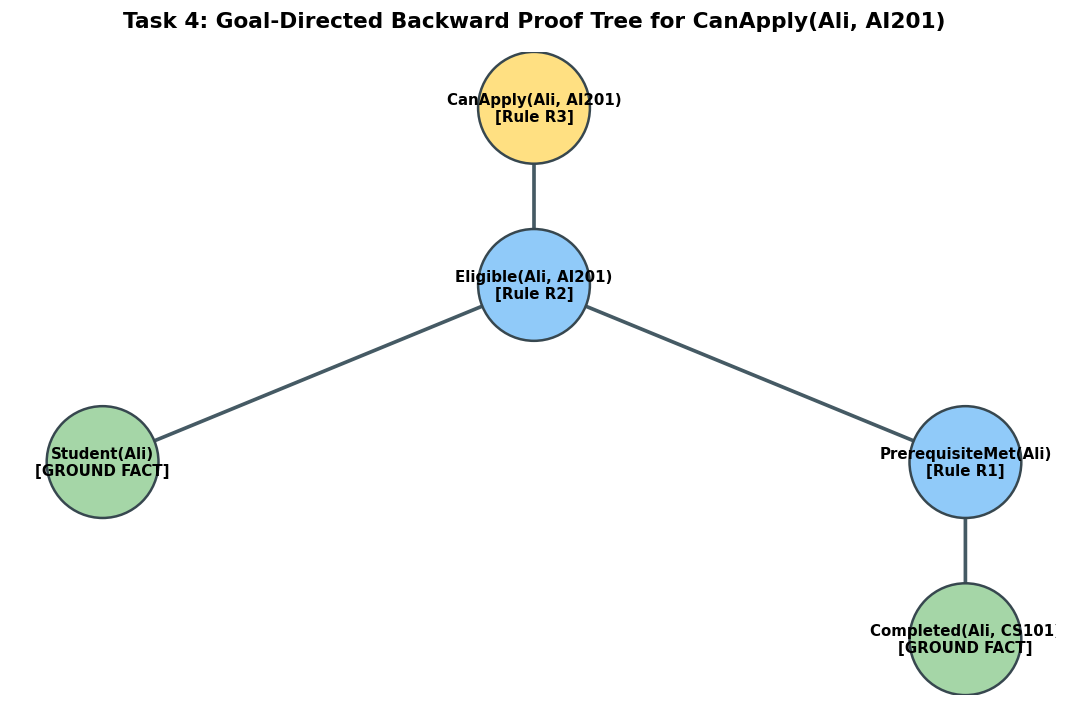

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

def print_proof_tree(tree, indent=0):
    """Renders proof trees in a clean hierarchical ASCII format."""
    prefix = "    " * indent
    node_type = tree[0]
    if node_type == "FACT":
        print(f"{prefix}└── [GROUND FACT] {tree[1]}")
    elif node_type in ("UNKNOWN", "CYCLE"):
        print(f"{prefix}└── [{node_type}] {tree[1]}")
    else:
        rule_id, goal_node, children = tree[0], tree[1], tree[2]
        print(f"{prefix}├── [RULE {rule_id}] Goal: {goal_node}")
        for child in children:
            print_proof_tree(child, indent + 1)

print("--- Task 4 Exercise: Hierarchical ASCII Proof Tree for Ali ---")
ok_ali, ali_tree = prove(("CanApply", "Ali", "AI201"), base_facts, rules)
print_proof_tree(ali_tree)

# 2. Add a second route to CanApply via Department Waiver to test OR reasoning
extended_rules = list(rules) + [
    {
        "id": "R4_Waiver",
        "if": [("DepartmentWaiver", "?x", "AI201")],
        "then": ("CanApply", "?x", "AI201"),
        "priority": 1
    }
]

# Grant Sara a department prerequisite waiver
facts_with_waiver = base_facts | {("DepartmentWaiver", "Sara", "AI201")}

print("\n--- Task 4 Exercise: Testing OR Reasoning (Alternative Route for Sara) ---")
ok_sara_waiver, sara_waiver_tree = prove(("CanApply", "Sara", "AI201"), facts_with_waiver, extended_rules)
print(f"Goal CanApply(Sara, AI201) -> {'PROVED' if ok_sara_waiver else 'NOT PROVED'}")
print("Proof Tree via Alternative Waiver Route:")
print_proof_tree(sara_waiver_tree)

# 3. High-Resolution NetworkX & Matplotlib Visual Proof Tree
G_proof = nx.DiGraph()
proof_nodes = [
    ("goal", "CanApply(Ali, AI201)\n[Rule R3]", "#FFE082"),
    ("sub1", "Eligible(Ali, AI201)\n[Rule R2]", "#90CAF9"),
    ("f1", "Student(Ali)\n[GROUND FACT]", "#A5D6A7"),
    ("sub2", "PrerequisiteMet(Ali)\n[Rule R1]", "#90CAF9"),
    ("f2", "Completed(Ali, CS101)\n[GROUND FACT]", "#A5D6A7")
]

for nid, label, col in proof_nodes:
    G_proof.add_node(nid, label=label, color=col)

proof_edges = [
    ("goal", "sub1"),
    ("sub1", "f1"),
    ("sub1", "sub2"),
    ("sub2", "f2")
]
G_proof.add_edges_from(proof_edges)

pos_proof = {
    "goal": (0, 3),
    "sub1": (0, 2),
    "f1": (-1.6, 1),
    "sub2": (1.6, 1),
    "f2": (1.6, 0)
}

plt.figure(figsize=(9, 6), dpi=120)
plt.title("Task 4: Goal-Directed Backward Proof Tree for CanApply(Ali, AI201)", fontsize=13, fontweight="bold", pad=15)
node_cols = [G_proof.nodes[n]["color"] for n in G_proof.nodes]
nx.draw_networkx_nodes(G_proof, pos_proof, node_color=node_cols, node_size=4500, edgecolors="#37474F", linewidths=1.5)
nx.draw_networkx_edges(G_proof, pos_proof, arrows=True, arrowstyle="-|>", arrowsize=22, edge_color="#455A64", width=2.2)
node_lbls = {n: G_proof.nodes[n]["label"] for n in G_proof.nodes}
nx.draw_networkx_labels(G_proof, pos_proof, labels=node_lbls, font_size=9, font_weight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

**Interpretation of Results (Task 4):**
The backward chaining proof tree illustrates top-down goal reduction: `CanApply(Ali, AI201)` delegates to `Eligible(Ali, AI201)` via R3, which forks into conjunctive AND branches requiring both `Student(Ali)` (a base fact) and `PrerequisiteMet(Ali)` (derived via R1 from `Completed(Ali, CS101)`). When an alternative waiver rule R4 was introduced, Sara's goal was successfully proved via the waiver branch, validating disjunctive OR reasoning across candidate rules.

Crucially, in positive rule systems operating under the **Open-World Assumption (OWA)**, a result of `"NOT PROVED"` does not establish the negation $\neg \text{CanApply}(\text{Sara}, \text{AI201})$. Under OWA, the absence of an assertion indicates an epistemological gap (the fact is **UNKNOWN**), not ontological falsity. Sara might have completed an equivalent prerequisite at another university or received an unrecorded exemption.

## Task 5 — Match Joins Across Course Prerequisites

### Theoretical Background
Academic degree auditing requires joining course requirements with student completion histories:
- Rule `J1` joins `Requires(?c, ?p)` and `Completed(?s, ?p)` on prerequisite variable `?p`, deriving `Satisfied(?s, ?c, ?p)` for each individual requirement satisfied.
- **The Prerequisite Matching Caveat (Element-wise vs. Universal Fulfillment):**
  A student satisfying *one* prerequisite of a multi-prerequisite course is **not** necessarily eligible for the course. Universal satisfaction requires:
  $$\forall p. \left( \text{Requires}(c, p) \implies \text{Completed}(s, p) \right)$$
  Pure positive Horn rules match element-wise and cannot express universal set containment without an explicit Closed-World Assumption (CWA) asserting that the prerequisite list in the knowledge base is exhaustive.

In [9]:
# Task 5: Relational joins across prerequisites
course_facts = {
    ("Completed", "Ali", "CS101"),
    ("Completed", "Ali", "MATH101"),
    ("Requires", "AI301", "CS101"),
    ("Requires", "AI301", "MATH101")
}

join_rule = {
    "id": "J1",
    "if": [("Requires", "?c", "?p"), ("Completed", "?s", "?p")],
    "then": ("Satisfied", "?s", "?c", "?p"),
    "priority": 1
}

joined, join_trace = forward_chain(course_facts, [join_rule])
print("--- Task 5: Forward Chaining Prerequisite Joins ---")
print("Satisfied prerequisite atoms:")
for f in sorted(f for f in joined if f[0] == "Satisfied"):
    print(f"  {f}")

def all_prerequisites_recorded_as_done(student, course, known):
    """Checks if all required prerequisites for a course are completed by the student.
    Relies on an authoritative complete-list (closed-world) assumption."""
    required = {f[2] for f in known if len(f) == 3 and f[0] == "Requires" and f[1] == course}
    if not required:
        return "UNKNOWN (no complete prerequisite list supplied)"
    completed = {f[2] for f in known if len(f) == 3 and f[0] == "Completed" and f[1] == student}
    return required <= completed

print(f"\nCheck AI301 for Ali (Initial full completion): {all_prerequisites_recorded_as_done('Ali', 'AI301', joined)}")

--- Task 5: Forward Chaining Prerequisite Joins ---
Satisfied prerequisite atoms:
  ('Satisfied', 'Ali', 'AI301', 'CS101')
  ('Satisfied', 'Ali', 'AI301', 'MATH101')

Check AI301 for Ali (Initial full completion): True


### Task 5 Exercise: Partial Completion & The Completeness Assumption
**Exercise Requirements:**
1. Remove `Completed(Ali, MATH101)` from the fact base and rerun forward chaining.
2. State which `Satisfied` facts remain in working memory.
3. Test `all_prerequisites_recorded_as_done("Ali", "AI301", joined)` and inspect missing requirements.
4. Explain the extra completeness assumption needed before claiming that ALL prerequisites are fulfilled.

In [10]:
# Task 5 Exercise: Remove Completed(Ali, MATH101) and rerun
partial_course_facts = {
    ("Completed", "Ali", "CS101"),
    ("Requires", "AI301", "CS101"),
    ("Requires", "AI301", "MATH101")
}

partial_joined, partial_trace = forward_chain(partial_course_facts, [join_rule])

print("--- Task 5 Exercise: Rerun After Removing Completed(Ali, MATH101) ---")
print("Remaining Satisfied Facts:")
remaining_satisfied = sorted(f for f in partial_joined if f[0] == "Satisfied")
for f in remaining_satisfied:
    print(f"  {f}")

# Completeness check
is_done = all_prerequisites_recorded_as_done("Ali", "AI301", partial_joined)
print(f"\nAll prerequisites recorded as done for Ali in AI301? -> {is_done}")

required_ai301 = {f[2] for f in partial_joined if len(f) == 3 and f[0] == "Requires" and f[1] == "AI301"}
completed_ali = {f[2] for f in partial_joined if len(f) == 3 and f[0] == "Completed" and f[1] == "Ali"}
missing_reqs = required_ai301 - completed_ali

print(f"Required prerequisites for AI301 : {required_ai301}")
print(f"Completed prerequisites by Ali   : {completed_ali}")
print(f"Unfulfilled / Missing prerequisites: {missing_reqs}")

--- Task 5 Exercise: Rerun After Removing Completed(Ali, MATH101) ---
Remaining Satisfied Facts:
  ('Satisfied', 'Ali', 'AI301', 'CS101')

All prerequisites recorded as done for Ali in AI301? -> False
Required prerequisites for AI301 : {'CS101', 'MATH101'}
Completed prerequisites by Ali   : {'CS101'}
Unfulfilled / Missing prerequisites: {'MATH101'}


**Interpretation of Results (Task 5):**
Removing `Completed(Ali, MATH101)` leaves only `('Satisfied', 'Ali', 'AI301', 'CS101')` in working memory. The procedural check `all_prerequisites_recorded_as_done` correctly returns `False` because `{'MATH101'}` remains missing from Ali's completed records.

To validly conclude that a student has fulfilled *all* prerequisites, the reasoning engine must invoke a **Closed-World Assumption (CWA)** on prerequisites: it must assume that the set of `Requires` facts in the database is exhaustive and that no additional unrecorded prerequisites exist. In pure positive Horn logic under OWA, deriving that individual requirements are met cannot prove universal satisfaction without explicit negative domain closure axioms.

## Task 6 — Agenda and Conflict Resolution

### Theoretical Background
In production rule systems, when multiple rule instances match working memory simultaneously, they form the **conflict set (agenda)**.
- **Agenda Policy:** Determines the firing sequence using conflict resolution strategies such as:
  - **Salience / Priority:** Higher priority numbers execute first.
  - **Declaration Order:** Earlier declared rules break ties.
  - **Specificity / Recency:** Rules with more specific premises or matching newer facts take precedence.
- **Monotonicity in Positive Horn Rulebases:**
  In pure positive rule engines (without deletion, fact retraction, or negation-as-failure), every activated rule will eventually fire. Therefore, priority policies alter the *operational order* of inferences, but leave the final deductive closure mathematically identical.

In [11]:
# Task 6: Agenda and conflict resolution
agenda_facts = {("HighScore", "Ali"), ("VerifiedID", "Ali")}
agenda_rules = [
    {
        "id": "A1",
        "if": [("HighScore", "?x")],
        "then": ("MeritCandidate", "?x"),
        "priority": 2
    },
    {
        "id": "A2",
        "if": [("VerifiedID", "?x")],
        "then": ("IdentityChecked", "?x"),
        "priority": 5
    }
]

def make_agenda(known, rulebase):
    """Generates and sorts eligible rule activations based on priority, order, and conclusion."""
    agenda = []
    for order, rule in enumerate(rulebase):
        for binding in match_all(rule["if"], known):
            conclusion = instantiate(rule["then"], binding)
            if conclusion not in known:
                agenda.append((rule["priority"], order, rule["id"], conclusion))
    # Higher priority first (-prio), followed by declaration order, followed by conclusion
    return sorted(agenda, key=lambda a: (-a[0], a[1], a[3]))

print("--- Task 6: Original Agenda (Highest Priority First) ---")
for activation in make_agenda(agenda_facts, agenda_rules):
    prio, order, rid, conc = activation
    print(f"  Activation: Priority {prio} | DeclOrder {order} | Rule [{rid}] => Proposes {conc}")

--- Task 6: Original Agenda (Highest Priority First) ---
  Activation: Priority 5 | DeclOrder 1 | Rule [A2] => Proposes ('IdentityChecked', 'Ali')
  Activation: Priority 2 | DeclOrder 0 | Rule [A1] => Proposes ('MeritCandidate', 'Ali')


### Task 6 Exercise: Priority Reversal & Agenda Conflicts vs. Semantic Incompatibilities
**Exercise Requirements:**
1. Reverse the priorities (A1 -> priority 5, A2 -> priority 2) and compare the resulting agenda.
2. Formally check whether the final positive deductive closure changes.
3. Distinguish an **agenda conflict** (operational scheduling) from **incompatible conclusions** (semantic contradiction).

In [12]:
# Task 6 Exercise: Reverse the priorities of A1 and A2
reversed_agenda_rules = [
    {
        "id": "A1",
        "if": [("HighScore", "?x")],
        "then": ("MeritCandidate", "?x"),
        "priority": 5
    },
    {
        "id": "A2",
        "if": [("VerifiedID", "?x")],
        "then": ("IdentityChecked", "?x"),
        "priority": 2
    }
]

print("--- Task 6 Exercise: Reversed Agenda Ordering ---")
for activation in make_agenda(agenda_facts, reversed_agenda_rules):
    prio, order, rid, conc = activation
    print(f"  Activation: Priority {prio} | DeclOrder {order} | Rule [{rid}] => Proposes {conc}")

# Deductive closure verification
closure_orig, _ = forward_chain(agenda_facts, agenda_rules)
closure_rev, _ = forward_chain(agenda_facts, reversed_agenda_rules)

print("\n--- Closure Invariance Verification ---")
print(f"Closure with original priorities: {sorted(closure_orig)}")
print(f"Closure with reversed priorities: {sorted(closure_rev)}")
print(f"Are closures mathematically identical? -> {closure_orig == closure_rev}")

--- Task 6 Exercise: Reversed Agenda Ordering ---
  Activation: Priority 5 | DeclOrder 0 | Rule [A1] => Proposes ('MeritCandidate', 'Ali')
  Activation: Priority 2 | DeclOrder 1 | Rule [A2] => Proposes ('IdentityChecked', 'Ali')

--- Closure Invariance Verification ---
Closure with original priorities: [('HighScore', 'Ali'), ('IdentityChecked', 'Ali'), ('MeritCandidate', 'Ali'), ('VerifiedID', 'Ali')]
Closure with reversed priorities: [('HighScore', 'Ali'), ('IdentityChecked', 'Ali'), ('MeritCandidate', 'Ali'), ('VerifiedID', 'Ali')]
Are closures mathematically identical? -> True


**Interpretation of Results (Task 6):**
Reversing priorities inverted the agenda ordering: Rule A1 (priority 5) was placed ahead of Rule A2 (priority 2). However, the final positive-rule closure remained completely invariant: `{'HighScore', 'IdentityChecked', 'MeritCandidate', 'VerifiedID'}`.

This highlights the vital distinction between an **agenda conflict** and **incompatible conclusions**:
- An **agenda conflict** is an operational execution choice: multiple rules are simultaneously eligible to fire, and the scheduler must decide which rule fires first.
- **Incompatible conclusions** are semantic/logical contradictions where two derived assertions (such as `RecommendApproval` and `HoldApproval`) cannot both hold in the real world. Prioritizing one rule over another in the agenda determines derivation order, but does not resolve the underlying semantic contradiction.

## Task 7 — Detect Competing Recommendations

### Theoretical Background
In multi-factor review domains (such as grant or loan applications), distinct evidence streams can trigger competing recommendations:
- High fraud risk triggers `HoldApproval(x)`.
- Verified documentation triggers `RecommendApproval(x)`.
- **Classical Logic vs. Positive Rulebases:**
  In pure positive First-Order Logic, `HoldApproval` and `RecommendApproval` are independent atomic relations. The inference engine simply derives both facts monotonically without crashing or detecting a contradiction, because it has no axiom stating that they are disjoint.
- To enforce domain integrity, the knowledge engineer must define an explicit **Incompatibility Policy** and an auditing layer to trap conflicting recommendations for human intervention.

In [13]:
# Task 7: Review rules and competing recommendations
review_facts = {("VerifiedDocuments", "App1"), ("FraudFlag", "App1")}
review_rules = [
    {
        "id": "C1",
        "if": [("HighRisk", "?x")],
        "then": ("HoldApproval", "?x"),
        "priority": 3
    },
    {
        "id": "C2",
        "if": [("VerifiedDocuments", "?x")],
        "then": ("RecommendApproval", "?x"),
        "priority": 1
    },
    {
        "id": "C3",
        "if": [("FraudFlag", "?x")],
        "then": ("HighRisk", "?x"),
        "priority": 5
    }
]

review_closure, review_trace = forward_chain(review_facts, review_rules)

print("--- Task 7: Forward Chaining Trace for Application Review ---")
for r, conclusion, binding in review_trace:
    print(f"  Rule [{r}] => {conclusion} using {binding}")

competing = [
    ("HoldApproval", x) in review_closure and ("RecommendApproval", x) in review_closure
    for x in ["App1"]
]
print(f"\nCompeting recommendations detected for App1: {any(competing)}")

--- Task 7: Forward Chaining Trace for Application Review ---
  Rule [C2] => ('RecommendApproval', 'App1') using {'?x': 'App1'}
  Rule [C3] => ('HighRisk', 'App1') using {'?x': 'App1'}
  Rule [C1] => ('HoldApproval', 'App1') using {'?x': 'App1'}

Competing recommendations detected for App1: True


### Task 7 Exercise: Explicit Policy Enforcement, Human Review, and Logical Semantics
**Exercise Requirements:**
1. Define an explicit policy matrix declaring `HoldApproval` and `RecommendApproval` incompatible.
2. Implement an automated audit function to detect the conflict and flag the application.
3. Propose a formal human-review governance protocol to resolve the conflict.
4. Explain why these two positive atoms do not constitute a classical logical contradiction without additional axioms.

In [14]:
# Task 7 Exercise: Incompatibility Policy Specification and Auditing Function
incompatible_recommendation_pairs = [
    ("HoldApproval", "RecommendApproval")
]

def audit_competing_recommendations(closure, conflict_pairs):
    """Audits working memory for incompatible pairs of recommendations."""
    detected_conflicts = []
    entities = {fact[1] for fact in closure if len(fact) >= 2}
    for entity in sorted(entities):
        for rec1, rec2 in conflict_pairs:
            has_rec1 = (rec1, entity) in closure
            has_rec2 = (rec2, entity) in closure
            if has_rec1 and has_rec2:
                detected_conflicts.append({
                    "entity": entity,
                    "conflict_pair": (rec1, rec2),
                    "severity": "CRITICAL_POLICY_DISCREPANCY",
                    "status": "AUTO_PROCESSING_HALTED"
                })
    return detected_conflicts

audit_results = audit_competing_recommendations(review_closure, incompatible_recommendation_pairs)

print("--- Task 7 Exercise: Policy Audit Report ---")
for audit in audit_results:
    print(f"• Target Entity   : {audit['entity']}")
    print(f"  Conflicting Claims: {audit['conflict_pair'][0]} AND {audit['conflict_pair'][1]}")
    print(f"  System Severity   : {audit['severity']}")
    print(f"  Action Taken      : {audit['status']}")

print("""
--- Proposed Human Review Governance Protocol ---
1. Automated Suspension: Immediately intercept and freeze automatic approval/denial workflows for App1.
2. Independent Source Verification: Fraud Compliance Officer re-verifies the origin of FraudFlag with security intelligence.
3. Document Cross-Examination: Registrar manually authenticates submitted academic transcripts against issuing university registries.
4. Executive Override Determination: A human adjudication panel records an authorized override, revoking one of the competing recommendations.""")

--- Task 7 Exercise: Policy Audit Report ---
• Target Entity   : App1
  Conflicting Claims: HoldApproval AND RecommendApproval
  System Severity   : CRITICAL_POLICY_DISCREPANCY
  Action Taken      : AUTO_PROCESSING_HALTED

--- Proposed Human Review Governance Protocol ---
1. Automated Suspension: Immediately intercept and freeze automatic approval/denial workflows for App1.
2. Independent Source Verification: Fraud Compliance Officer re-verifies the origin of FraudFlag with security intelligence.
3. Document Cross-Examination: Registrar manually authenticates submitted academic transcripts against issuing university registries.
4. Executive Override Determination: A human adjudication panel records an authorized override, revoking one of the competing recommendations.


**Interpretation of Results (Task 7):**
The forward chaining engine derived both `HoldApproval(App1)` and `RecommendApproval(App1)` because both rules fired legitimately from positive evidence.

In classical mathematical logic, these two positive atoms do **not** constitute a formal contradiction $(\bot)$ because positive atomic relations have independent semantic interpretations; there exists a valid model where both relations contain `App1`. To make this a classical contradiction, the theory must be augmented with an explicit negative disjointness axiom:
$$\forall x. \neg \left( \text{HoldApproval}(x) \land \text{RecommendApproval}(x) \right) \quad \text{or in DL:} \quad \text{HoldApproval} \sqcap \text{RecommendApproval} \sqsubseteq \bot$$
Without such axioms, the policy auditing layer must programmatically trap incompatible pairs to ensure sound business governance.

## Task 8 — Mini Expert System Challenge and Validation

### Theoretical Background
An expert system integrates domain facts, inference rules, and explanation capabilities:
- **Positive Evidence Requirement:** To maintain integrity, compliance decisions (e.g., lack of disciplinary violations) must be supported by explicit positive evidence (`NoViolationVerified`), rather than treating the absence of an infraction record as proof of innocence (which is a dangerous closed-world fallacy).
- Below, we implement the baseline scholarship advisor and then expand it into a full multi-criteria academic expert system.

In [15]:
# Task 8: Base Scholarship Knowledge Base
scholarship_facts = {
    ("Student", "Sara"),
    ("StrongCGPA", "Sara"),
    ("NoViolationVerified", "Sara")
}

scholarship_rules = [
    {
        "id": "S1",
        "if": [("Student", "?x"), ("StrongCGPA", "?x")],
        "then": ("MeritCandidate", "?x"),
        "priority": 1
    },
    {
        "id": "S2",
        "if": [("MeritCandidate", "?x"), ("NoViolationVerified", "?x")],
        "then": ("RecommendScholarship", "?x"),
        "priority": 1
    }
]

sch_closure, sch_trace = forward_chain(scholarship_facts, scholarship_rules)
print("--- Task 8: Base Scholarship Advisor ---")
print("Forward chaining trace:")
for r, conc, b in sch_trace:
    print(f"  Rule [{r}] => {conc} using {b}")

ok_base, tree_base = prove(("RecommendScholarship", "Sara"), scholarship_facts, scholarship_rules)
print(f"\nBackward proving RecommendScholarship(Sara) -> {'PROVED' if ok_base else 'NOT PROVED'}")
print(f"Proof tree: {tree_base}")

--- Task 8: Base Scholarship Advisor ---
Forward chaining trace:
  Rule [S1] => ('MeritCandidate', 'Sara') using {'?x': 'Sara'}
  Rule [S2] => ('RecommendScholarship', 'Sara') using {'?x': 'Sara'}

Backward proving RecommendScholarship(Sara) -> PROVED
Proof tree: ('S2', ('RecommendScholarship', 'Sara'), [('S1', ('MeritCandidate', 'Sara'), [('FACT', ('Student', 'Sara')), ('FACT', ('StrongCGPA', 'Sara'))]), ('FACT', ('NoViolationVerified', 'Sara'))])


### Task 8 Exercise: Comprehensive Multi-Path Scholarship Expert System
**Specification Requirements:**
- **$\ge 5$ Rules:** Multi-tiered rules incorporating academic merit, financial need, disciplinary verification, and committee recommendations.
- **$\ge 5$ Ground Facts:** Multi-student cohort (Sara, Tariq, Ayesha, Bilal) with varied credentials.
- **$\ge 2$ Intermediate Derived Facts:** `AcademicExcellence`, `NeedEligible`, and `MeritCandidate`.
- **1 Final Recommendation:** `RecommendScholarship(?x)`.
- **Dual Inference Strategies:** Forward chaining over cohort + backward chaining proof trees.
- **Handling UNKNOWN Goals:** Demonstrate open-world behavior when evidence is unasserted.
- **Rule Dependency Visual Graph:** NetworkX & Matplotlib diagram of the expert architecture.
- **Data Quality & Policy Critique:** 4–5 sentences analyzing positive assertion requirements and real-world system limitations.

--- Task 8 Exercise: Forward Chaining Trace on Student Cohort ---
Step  1: [S1_Merit          ] => ('AcademicExcellence', 'Sara')   using {'?x': 'Sara'}
Step  2: [S1_Merit          ] => ('AcademicExcellence', 'Tariq')  using {'?x': 'Tariq'}
Step  3: [S2_Need           ] => ('NeedEligible', 'Ayesha')       using {'?x': 'Ayesha'}
Step  4: [S3_MeritCand_Acad ] => ('MeritCandidate', 'Sara')       using {'?x': 'Sara'}
Step  5: [S4_MeritCand_Need ] => ('MeritCandidate', 'Ayesha')     using {'?x': 'Ayesha'}
Step  6: [S5_FinalRec       ] => ('RecommendScholarship', 'Ayesha') using {'?x': 'Ayesha'}
Step  7: [S5_FinalRec       ] => ('RecommendScholarship', 'Sara') using {'?x': 'Sara'}

--- Final Scholarship Recommendations Derived ---
  ★ Approved Awardee: Ayesha -> ('RecommendScholarship', 'Ayesha')
  ★ Approved Awardee: Sara -> ('RecommendScholarship', 'Sara')

--- Task 8 Exercise: Goal-Directed Backward Proofs ---

Query: ('RecommendScholarship', 'Sara') -> PROVED (Award Granted)
Detailed Exp

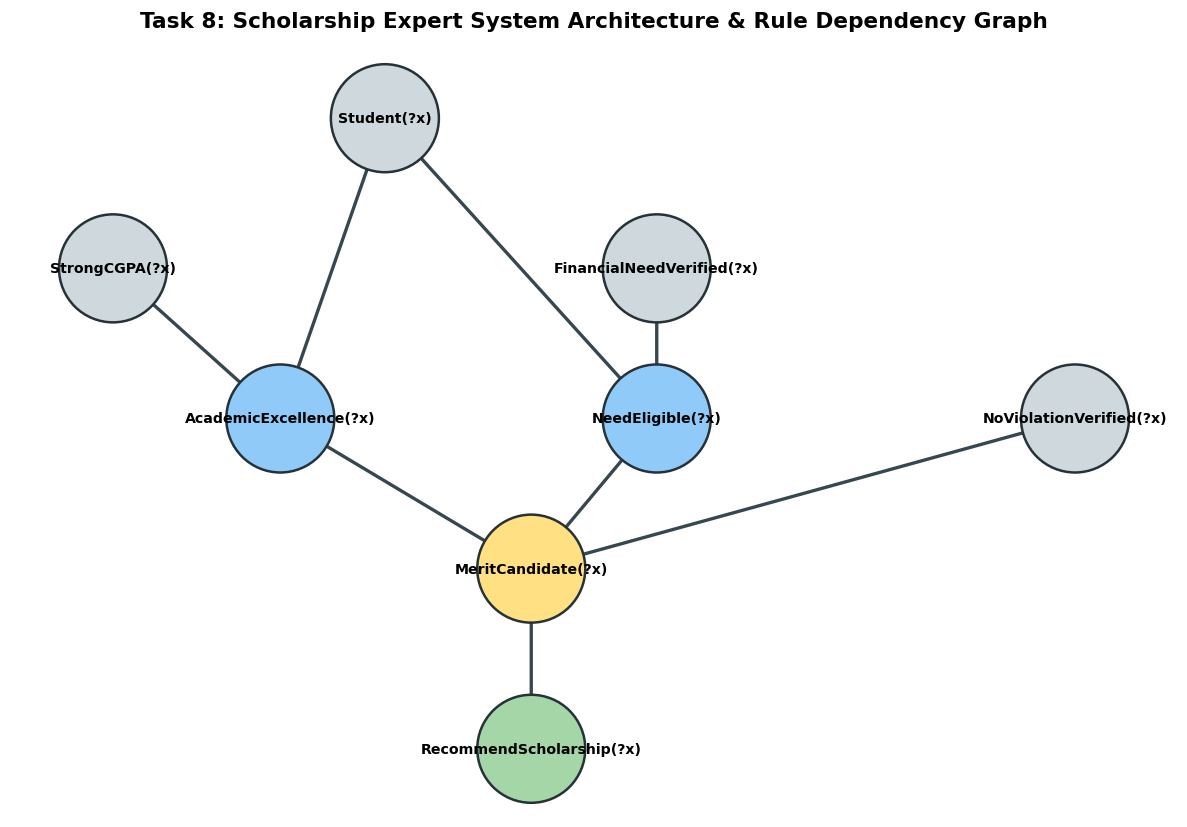

In [16]:
# Task 8 Exercise: Expanded Expert System Knowledge Base

# 1. Expanded Ground Facts across 4 diverse student profiles (9 facts total)
expanded_scholarship_facts = {
    # Sara: Exemplary academic record + verified conduct
    ("Student", "Sara"),
    ("StrongCGPA", "Sara"),
    ("ExtracurricularExcellence", "Sara"),
    ("NoViolationVerified", "Sara"),

    # Tariq: High academic achievement, but conduct clearance is unverified / pending
    ("Student", "Tariq"),
    ("StrongCGPA", "Tariq"),

    # Ayesha: Documented financial need + verified conduct
    ("Student", "Ayesha"),
    ("FinancialNeedVerified", "Ayesha"),
    ("NoViolationVerified", "Ayesha"),

    # Bilal: Student with an active disciplinary infraction
    ("Student", "Bilal"),
    ("DisciplinaryWarning", "Bilal")
}

# 2. Expanded Rule Base (5 rules)
# Intermediate facts: AcademicExcellence, NeedEligible, MeritCandidate
# Final recommendation: RecommendScholarship
expanded_scholarship_rules = [
    {
        "id": "S1_Merit",
        "if": [("Student", "?x"), ("StrongCGPA", "?x")],
        "then": ("AcademicExcellence", "?x"),
        "priority": 3
    },
    {
        "id": "S2_Need",
        "if": [("Student", "?x"), ("FinancialNeedVerified", "?x")],
        "then": ("NeedEligible", "?x"),
        "priority": 3
    },
    {
        "id": "S3_MeritCand_Acad",
        "if": [("AcademicExcellence", "?x"), ("NoViolationVerified", "?x")],
        "then": ("MeritCandidate", "?x"),
        "priority": 2
    },
    {
        "id": "S4_MeritCand_Need",
        "if": [("NeedEligible", "?x"), ("NoViolationVerified", "?x")],
        "then": ("MeritCandidate", "?x"),
        "priority": 2
    },
    {
        "id": "S5_FinalRec",
        "if": [("MeritCandidate", "?x")],
        "then": ("RecommendScholarship", "?x"),
        "priority": 1
    }
]

# Forward Chaining Execution
exp_closure, exp_trace = forward_chain(expanded_scholarship_facts, expanded_scholarship_rules)

print("--- Task 8 Exercise: Forward Chaining Trace on Student Cohort ---")
for step, (rid, conc, b) in enumerate(exp_trace, 1):
    print(f"Step {step:2d}: [{rid:<18}] => {str(conc):<32} using {b}")

print("\n--- Final Scholarship Recommendations Derived ---")
for fact in sorted(f for f in exp_closure if f[0] == "RecommendScholarship"):
    print(f"  ★ Approved Awardee: {fact[1]} -> {fact}")

# Backward Chaining Demonstrations on Cohort
print("\n--- Task 8 Exercise: Goal-Directed Backward Proofs ---")
cohort_queries = [
    ("RecommendScholarship", "Sara"),    # Proved via Academic Excellence
    ("RecommendScholarship", "Ayesha"),  # Proved via Financial Need
    ("RecommendScholarship", "Tariq"),   # UNKNOWN (Conduct verification pending)
    ("RecommendScholarship", "Bilal")    # UNKNOWN (No qualifying criteria)
]

for q in cohort_queries:
    student_name = q[1]
    ok, ptree = prove(q, expanded_scholarship_facts, expanded_scholarship_rules)
    status_str = "PROVED (Award Granted)" if ok else "UNKNOWN (Open-World Lack of Proof)"
    print(f"\nQuery: {q} -> {status_str}")
    if ok:
        print("Detailed Explanation Tree:")
        print_proof_tree(ptree)
    else:
        print(f"Explanation: Cannot derive recommendation because sub-goal is missing from assertions: {ptree}")

# Visual Architecture: Rule Dependency and Inference Graph
G_exp = nx.DiGraph()
concept_nodes = [
    ("Student(?x)", "#CFD8DC"),
    ("StrongCGPA(?x)", "#CFD8DC"),
    ("FinancialNeedVerified(?x)", "#CFD8DC"),
    ("NoViolationVerified(?x)", "#CFD8DC"),
    ("AcademicExcellence(?x)", "#90CAF9"),
    ("NeedEligible(?x)", "#90CAF9"),
    ("MeritCandidate(?x)", "#FFE082"),
    ("RecommendScholarship(?x)", "#A5D6A7")
]

for node, color in concept_nodes:
    G_exp.add_node(node, color=color)

flow_edges = [
    ("Student(?x)", "AcademicExcellence(?x)"),
    ("StrongCGPA(?x)", "AcademicExcellence(?x)"),
    ("Student(?x)", "NeedEligible(?x)"),
    ("FinancialNeedVerified(?x)", "NeedEligible(?x)"),
    ("AcademicExcellence(?x)", "MeritCandidate(?x)"),
    ("NeedEligible(?x)", "MeritCandidate(?x)"),
    ("NoViolationVerified(?x)", "MeritCandidate(?x)"),
    ("MeritCandidate(?x)", "RecommendScholarship(?x)")
]
G_exp.add_edges_from(flow_edges)

pos_exp = {
    "Student(?x)": (-2.5, 2),
    "StrongCGPA(?x)": (-3.8, 1),
    "FinancialNeedVerified(?x)": (-1.2, 1),
    "NoViolationVerified(?x)": (0.8, 0),
    "AcademicExcellence(?x)": (-3.0, 0),
    "NeedEligible(?x)": (-1.2, 0),
    "MeritCandidate(?x)": (-1.8, -1),
    "RecommendScholarship(?x)": (-1.8, -2.2)
}

plt.figure(figsize=(10, 7), dpi=120)
plt.title("Task 8: Scholarship Expert System Architecture & Rule Dependency Graph", fontsize=13, fontweight="bold", pad=15)
cols = [G_exp.nodes[n]["color"] for n in G_exp.nodes]
nx.draw_networkx_nodes(G_exp, pos_exp, node_color=cols, node_size=4200, edgecolors="#263238", linewidths=1.5)
nx.draw_networkx_edges(G_exp, pos_exp, arrows=True, arrowstyle="-|>", arrowsize=20, edge_color="#37474F", width=2.0)
nx.draw_networkx_labels(G_exp, pos_exp, font_size=8.5, font_weight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

**Interpretation of Results & Policy Critique (Task 8):**
The expanded expert system successfully handles multiple qualifying pathways (academic excellence for Sara and financial need for Ayesha) through disjunctive rule branches (S3 and S4) converging into `MeritCandidate(?x)` and finally `RecommendScholarship(?x)`. Both forward chaining on the cohort and backward chaining on individual student queries yielded consistent, explainable results.

**Critical Data-Quality and Policy Limitation Analysis:**
Requiring explicit positive assertions such as `NoViolationVerified` enforces institutional safety by preventing the dangerous closed-world assumption that "the absence of an infraction in the database proves spotless conduct." However, in production university environments, this strict positive-evidence requirement introduces significant administrative latency, as students whose background clearances are delayed by registrar backlogs are classified as `UNKNOWN` and withheld from consideration despite flawless actual behavior. Furthermore, binary predicates like `StrongCGPA` impose brittle hard thresholds that ignore curriculum difficulty, grade deflation across departments, or holistic socioeconomic context. Addressing these limitations in industrial systems requires certainty factors, multi-criteria fuzzy scoring, and asynchronous evidence integration.

## Executive Post-Lab Report & Theoretical Synthesis

### 1. Architectural Summary of the University Rule Base
The developed rule-based reasoning system provides a complete, modular environment for finite, positive Horn clause deduction. The table below summarizes the formal architecture implemented across the laboratory tasks:

| Component Type | Symbol / ID | Antecedent (IF) | Consequent (THEN) | Role & Semantics |
| :--- | :--- | :--- | :--- | :--- |
| **Ground Fact** | Base Assertions | None (Axiomatic) | `Student(x)`, `Completed(x, c)` | Positive atomic facts in working memory |
| **Rule** | `R1` | `Completed(?x, CS101)` | `PrerequisiteMet(?x)` | Course prerequisite mapping |
| **Rule** | `R2` | `Student(?x) ∧ PrerequisiteMet(?x)` | `Eligible(?x, AI201)` | Relational join across student status & prerequisites |
| **Rule** | `R3` | `Eligible(?x, AI201)` | `CanApply(?x, AI201)` | Application authorization |
| **Rule** | `J1` | `Requires(?c, ?p) ∧ Completed(?s, ?p)` | `Satisfied(?s, ?c, ?p)` | Multi-variable cross-course prerequisite join |
| **Rule** | `A1` / `A2` | `HighScore(?x)` / `VerifiedID(?x)` | `MeritCandidate(?x)` / `IdentityChecked(?x)` | Salience and priority agenda sequencing |
| **Rule** | `C1`, `C2`, `C3`| `HighRisk(?x)`, `VerifiedDocs(?x)`, etc. | `HoldApproval(?x)`, `RecommendApproval(?x)` | Multi-factor review with policy conflict potential |
| **Expert Rules** | `S1`–`S5` | Academic & need conditions | `AcademicExcellence`, `MeritCandidate`, `RecommendScholarship` | Tiered scholarship advising expert system |

---

### 2. Forward Chaining vs. Backward Chaining Comparison
The laboratory demonstrated both major inference paradigms over identical knowledge representations:

| Dimension | Forward Chaining (Data-Driven) | Backward Chaining (Goal-Directed) |
| :--- | :--- | :--- |
| **Starting Point** | Working memory containing known ground facts | Target query / goal hypothesis |
| **Reasoning Flow** | Antecedents $\longrightarrow$ Consequents (Bottom-up) | Consequents $\longrightarrow$ Supporting Premises (Top-down) |
| **Search Structure** | Monotonic saturation to fixed-point closure | AND/OR proof tree search with cycle checking |
| **Completeness** | Computes the complete deductive closure | Proves or refutes a specific targeted goal |
| **Computational Cost** | High when fact base is large and few facts are relevant | Minimal when goal can be resolved along a shallow branch |
| **Best Suited For** | Batch auditing, real-time monitoring, event processing | Query answering, diagnostic troubleshooting, interactive advising |

---

### 3. Open-World Assumption (OWA) vs. Closed-World Assumption (CWA)
- **Open-World Assumption (Teaching Engine):** If a proposition cannot be proved from the rulebase and known assertions, the engine returns **`UNKNOWN`** (`NOT PROVED`). The absence of a fact in working memory is an epistemological limitation of the agent's current knowledge, not proof of falsity.
- **Closed-World Assumption (Relational Databases & Prolog):** If an atomic sentence cannot be derived, it is assumed to be **`FALSE`** (Negation as Failure).
- **Practical Impact in Academic Advising:**
  In Task 4 and Task 8, Sara and Tariq's goals were `NOT PROVED`. Under OWA, we interpret this as "insufficient evidence has been recorded." Under CWA, the system would erroneously assert that they are strictly disqualified, which could lead to wrongful rejection of students whose official paperwork is merely in transit.

---

### 4. The Prerequisite Matching Caveat (Element-wise vs. Set-Theoretic Completeness)
Task 5 illuminated an essential limitation of positive Horn rules:
- Rule `J1` matches element-wise: each completed prerequisite generates a separate `Satisfied` atom.
- However, completing *some* prerequisites does not entail completing *all* prerequisites. In first-order logic, verifying that all requirements are met requires universal quantification:
  $$\forall p. \left( \text{Requires}(c, p) \implies \text{Completed}(s, p) \right)$$
- Standard Horn rules cannot express universal quantification or set difference without introducing negation (`NOT MissingPrerequisite(s, c)`). Consequently, universal compliance checking requires an explicit procedural completeness check (`all_prerequisites_recorded_as_done`) founded on an authoritative Closed-World Assumption regarding the course catalog.

---

### 5. Agenda Conflict Resolution vs. Logical Contradiction
- **Agenda Conflict:** An operational dilemma during forward chaining when multiple rules are ready to fire simultaneously. Conflict resolution strategies (priority, declaration order) determine which inference executes first. In pure positive Horn logic, the deductive closure is confluent and monotonic—priority ordering changes the trace order, but never the final set of derived truths.
- **Incompatible Conclusions (Semantic Conflicts):** Occur when two derived assertions represent mutually exclusive domain actions (e.g., `HoldApproval` and `RecommendApproval` in Task 7). In standard first-order logic, distinct positive predicate symbols are logically independent; both can simultaneously hold in a satisfying model. A classical contradiction $(\bot)$ only arises if an explicit negative integrity constraint is declared:
  $$\forall x. \neg \left( \text{HoldApproval}(x) \land \text{RecommendApproval}(x) \right)$$
  In production systems, this requires an external policy audit layer to halt processing and route the dossier to human adjudicators.

---

### 6. Answers to Post-Lab and Discussion Questions
1. **Why does R1 -> R2 -> R3 yield CanApply(Ali, AI201)?**
   Forward chaining operates in three sequential derivation cycles: Cycle 1 derives `PrerequisiteMet(Ali)` from `Completed(Ali, CS101)` via R1. Cycle 2 joins this new fact with `Student(Ali)` to fire R2, deriving `Eligible(Ali, AI201)`. Cycle 3 matches this eligibility atom against R3, deriving the final conclusion `CanApply(Ali, AI201)`.
2. **What stops the forward chaining engine?**
   The engine stops when the conflict set / candidate additions list is empty (`not additions`). Because newly derived conclusions are filtered against working memory (`conclusion not in known`), and the universe of terms is finite and positive, the system reaches a monotonic fixed point where no new facts can be generated.
3. **Why does "NOT PROVED" not establish a negative fact?**
   Under the Open-World Assumption, the failure to prove a proposition means only that the current knowledge base lacks sufficient axioms to entail it. It does not entail that the proposition's negation is true.
4. **How should competing recommendations be managed in production AI systems?**
   Systems should implement an automated policy monitoring layer that checks working memory against an incompatibility matrix. When competing recommendations are derived, automated actions must be suspended, an audit incident logged, and the file escalated to a human review committee with an explanatory trace.